# Balance Checks & McCray Test

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdrobust import rdrobust
from rdrobust import rdplot
from rddensity import rddensity, rdplotdensity
import re

In [2]:
df_rdd = pd.read_csv('df_rdd_clean.csv')

In [3]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,skill_share_pre,skill_share_trend,delta_skill_share,pop_pre,pop_post,gender_gap_tertiary,no_diploma_share,far_right_participated,income_median,income_gini,unemployment_rate
0,1053,LUG,437,2014,t1,False,0,-2.409639,0.384403,0.028441,0.022447,27505.0,28030.0,-0.000504,0.615597,True,17694.500000,0.365057,17.997301
1,1053,LUG,388,2020,t1,False,0,-4.088756,0.406850,0.022447,0.022403,28030.0,28927.0,-0.005866,0.593150,True,18276.111111,0.375722,17.078005
2,2168,LDVG,335,2014,t1,False,0,-5.130327,0.322229,0.049262,0.016947,9906.0,10098.0,0.005124,0.677771,True,17063.666667,0.368367,22.861113
3,2168,LDVC,264,2020,t1,False,0,-5.420827,0.339176,0.016947,-0.009506,10098.0,10374.0,-0.031530,0.660824,True,17170.000000,0.387833,23.566623
4,2173,LDVD,315,2014,t2,False,0,-4.599702,0.275587,0.049451,0.039119,8266.0,8160.0,0.022809,0.724413,True,15662.666667,0.399675,24.051101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,95491,LDVD,386,2014,t1,False,0,-8.980798,0.500472,0.061387,0.044734,5293.0,5497.0,-0.017223,0.499528,True,NaN,NaN,8.661228
833,95563,LUMP,411,2014,t1,False,0,-5.092448,0.537022,0.048996,0.034063,10048.0,10403.0,0.002764,0.462978,True,28190.666667,0.309148,10.062158
834,95607,LUG,344,2008,t1,False,0,-3.158237,0.368726,0.024197,0.111584,16576.0,17293.0,0.007391,0.631274,True,22209.000000,0.309100,8.712611
835,95607,LUMP,462,2014,t2,False,0,-3.745754,0.480310,0.049311,0.035686,17293.0,17504.0,0.009470,0.519690,True,23755.090909,0.303520,10.358991


## Balance Checks

In [4]:
# Check d_50 range within each election cycle
for y in [2008, 2014, 2020]:
    sub = df_rdd[df_rdd['election_year'] == y]['d_50']
    print(f"{y}: min={sub.min():.2f}, max={sub.max():.2f}, n_treated={sub[sub>0].count()}, n_control={sub[sub<=0].count()}")

2008: min=-51.13, max=-0.23, n_treated=0, n_control=39
2014: min=-70.42, max=3.34, n_treated=13, n_control=500
2020: min=-28.92, max=11.59, n_treated=13, n_control=272


#### Data Limitation
- **No treated units in year 2008**
So I add try and except statement to skipp 2008 if necessary

Note on 2008: No commune in the 2008 sample has d_50 > 0, meaning the far-right won a plurality in none of the observed elections that year. Since we require observations on both sides of the cutoff to fit two local regressions, the cutoff c=0 falls outside the empirical support of d_50 and estimation is not possible. We therefore exclude 2008 from all balance checks and from the main Diff-in-Disc estimation, and report this as a sample limitation.

In [5]:
def balance_check(df, covariate, running='d_50', cutoff=0, cycle=None):
    """Run rdrobust for one covariate, optionally restricted to one election cycle."""
    data = df.dropna(subset=[covariate, running])
    if cycle is not None:
        data = data[data['election_year'] == cycle]

    try:
        result = rdrobust(y=data[covariate], x=data[running], c=cutoff)
    except Exception as e:
        print(f"Skipped {covariate} ({cycle}): {e}")
        return None

    return {
    'covariate': covariate,                        # name of the covariate
    'cycle': cycle if cycle is not None else 'pooled',  # election year (2008/2014/2020)
    'coef': result.coef.loc['Robust'].values[0],   # estimated discontinuity (jump) in the covariate at the cutoff
    'se': result.se.loc['Robust'].values[0],       # standard error of that estimate (robust, bias-corrected)
    'pval': result.pv.loc['Robust'].values[0],     # p-value — probability of seeing a jump this large if there were truly no discontinuity
    'ci_lower': result.ci.loc['Robust'].values[0], # lower bound of the 95% confidence interval for the jump
    'ci_upper': result.ci.loc['Robust'].values[1], # upper bound of the 95% confidence interval for the jump
    'N': sum(result.N),                            # total observations used (N_left + N_right within the bandwidth), not a DataFrame
}

In [6]:
covariates = ['log_pop', 'skill_share_pre', 'skill_share_trend', 'gender_gap_tertiary',
              'no_diploma_share', 'income_median', 'income_gini', 'unemployment_rate']

In [7]:
df_rdd

,code_commune,nuance,voix,election_year,tour,is_far_right,treat,d_50,skill_share_pre,skill_share_trend,delta_skill_share,pop_pre,pop_post,gender_gap_tertiary,no_diploma_share,far_right_participated,income_median,income_gini,unemployment_rate
0,1053,LUG,437,2014,t1,False,0,-2.409639,0.384403,0.028441,0.022447,27505.0,28030.0,-0.000504,0.615597,True,17694.500000,0.365057,17.997301
1,1053,LUG,388,2020,t1,False,0,-4.088756,0.406850,0.022447,0.022403,28030.0,28927.0,-0.005866,0.593150,True,18276.111111,0.375722,17.078005
2,2168,LDVG,335,2014,t1,False,0,-5.130327,0.322229,0.049262,0.016947,9906.0,10098.0,0.005124,0.677771,True,17063.666667,0.368367,22.861113
3,2168,LDVC,264,2020,t1,False,0,-5.420827,0.339176,0.016947,-0.009506,10098.0,10374.0,-0.031530,0.660824,True,17170.000000,0.387833,23.566623
4,2173,LDVD,315,2014,t2,False,0,-4.599702,0.275587,0.049451,0.039119,8266.0,8160.0,0.022809,0.724413,True,15662.666667,0.399675,24.051101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,95491,LDVD,386,2014,t1,False,0,-8.980798,0.500472,0.061387,0.044734,5293.0,5497.0,-0.017223,0.499528,True,NaN,NaN,8.661228
833,95563,LUMP,411,2014,t1,False,0,-5.092448,0.537022,0.048996,0.034063,10048.0,10403.0,0.002764,0.462978,True,28190.666667,0.309148,10.062158
834,95607,LUG,344,2008,t1,False,0,-3.158237,0.368726,0.024197,0.111584,16576.0,17293.0,0.007391,0.631274,True,22209.000000,0.309100,8.712611
835,95607,LUMP,462,2014,t2,False,0,-3.745754,0.480310,0.049311,0.035686,17293.0,17504.0,0.009470,0.519690,True,23755.090909,0.303520,10.358991


In [8]:
# 1. Log population
df_rdd['log_pop'] = np.log(df_rdd['pop_pre'])
results = [balance_check(df_rdd, 'log_pop', cycle=y) for y in [2008, 2014, 2020]]
results = [balance_check(df_rdd, 'log_pop', cycle=y) for y in [2008, 2014, 2020]]
results = [r for r in results if r is not None]

Skipped log_pop (2008): c should be set within the range of x
Skipped log_pop (2008): c should be set within the range of x


**Log population**: Population size proxies for a commune's general character (urban/rural, economic base) and directly affects how d_50 behaves in plurality elections with few voters. If treated and control communes differ systematically in size, any downstream effect could just reflect "small vs. large towns," not treatment.

In [9]:
# 2. Pre-treatment skill share (level)
results += [balance_check(df_rdd, 'skill_share_pre', cycle=y) for y in [2008, 2014, 2020]]

Skipped skill_share_pre (2008): c should be set within the range of x


**Skill share, pre-treatment (level)**: This is the value of your outcome variable before the election. If it already differs at the cutoff, treated and control communes weren't comparable to begin with, which directly threatens the causal interpretation of delta_skill_share.

In [10]:
# 3. Pre-treatment skill share trend
results += [balance_check(df_rdd, 'skill_share_trend', cycle=y) for y in [2008, 2014, 2020]]

Skipped skill_share_trend (2008): c should be set within the range of x


**Skill share trend**: Checks whether communes were already moving in different directions in educated-population share before the election, not just sitting at different starting levels. A jump here would mean your Diff-in-Disc design needs the trend, not just the level, netted out.

In [11]:
# 4. Gender gap in tertiary education
results += [balance_check(df_rdd, 'gender_gap_tertiary', cycle=y) for y in [2008, 2014, 2020]]

Skipped gender_gap_tertiary (2008): c should be set within the range of x


**Gender gap in tertiary education**: Captures whether the balance of highly-educated men vs. women differs across the cutoff, which can reflect underlying differences in local economic structure (e.g. university towns, specific industries) rather than random assignment.

In [12]:
# 5. No-diploma share
results += [balance_check(df_rdd, 'no_diploma_share', cycle=y) for y in [2008, 2014, 2020]]

Skipped no_diploma_share (2008): c should be set within the range of x


**No-diploma share**: The mirror image of skill share, capturing the low-education end of the distribution. Checking it separately from skill share confirms there isn't a compositional imbalance skill share alone might miss.

In [13]:
# 6. Income median
results += [balance_check(df_rdd, 'income_median', cycle=y) for y in [2008, 2014, 2020]]

Skipped income_median (2008): c should be set within the range of x


**Income median**: A textbook confounder: income plausibly predicts both far-right vote share (economic-anxiety channel) and future skill composition (ability of high earners to move). If it's imbalanced, it's a live threat to your causal claim.

In [14]:
# 7. Income Gini
results += [balance_check(df_rdd, 'income_gini', cycle=y) for y in [2008, 2014, 2020]]

Skipped income_gini (2008): c should be set within the range of x


**Income Gini**: Captures inequality within a commune, separately from its average income level — two communes can have the same median but very different equality, and inequality independently correlates with political polarization.

In [15]:
# 8. Unemployment rate
results += [balance_check(df_rdd, 'unemployment_rate', cycle=y) for y in [2008, 2014, 2020]]

Skipped unemployment_rate (2008): c should be set within the range of x


**Unemployment rate**: The single most theoretically motivated confounder given the well-documented far-right/economic-distress link worldwide; if unemployed communes disproportionately elect the far-right and separately drive skilled outmigration, this variable sits directly on your identification's weakest point.

In [16]:
# ── Assemble final balance table ──
results = [r for r in results if r is not None]  # drop skipped (2008, empty-treatment) checks
balance_table = pd.DataFrame(results)
balance_table

,covariate,cycle,coef,se,pval,ci_lower,ci_upper,N
0,log_pop,2014,-1.962861,0.957140,0.040291,-3.838822,-0.086901,513
1,log_pop,2020,0.611386,1.525442,0.688573,-2.378426,3.601198,285
2,skill_share_pre,2014,-0.125148,0.062595,0.045574,-0.247832,-0.002463,513
3,skill_share_pre,2020,0.012211,0.070476,0.862441,-0.125919,0.150341,285
4,skill_share_trend,2014,0.021533,0.008982,0.016519,0.003928,0.039137,513
5,skill_share_trend,2020,-0.004679,0.005976,0.433617,-0.016392,0.007033,285
6,gender_gap_tertiary,2014,0.017820,0.021626,0.409921,-0.024565,0.060206,513
7,gender_gap_tertiary,2020,0.042455,0.012479,0.000669,0.017997,0.066912,285
8,no_diploma_share,2014,0.125148,0.062595,0.045574,0.002463,0.247832,513
9,no_diploma_share,2020,-0.012211,0.070476,0.862441,-0.150341,0.125919,285


In [17]:
def plot_balance_rdrobust(ax, df, covariate, running='d_50', cutoff=0, cycle=None, p=1):
    """p=1 (local linear) matches rdrobust's default point-estimate polynomial order —
    avoids the boundary overfitting that rdplot's default p=4 produces with small N.
    Standard RDD plot: color-coded scatter + one fitted line per side + cutoff marker."""

    # Drop rows where either the covariate or the running variable is missing —
    # rdplot can't handle NaN, and a missing d_50 would make the point unplaceable anyway.
    data = df.dropna(subset=[covariate, running])

    # If a specific election cycle was requested, restrict to just those rows
    # (otherwise all three years would get pooled together in one plot).
    if cycle is not None:
        data = data[data['election_year'] == cycle]

    # Try to run rdrobust's own rdplot function. hide=True stops it from drawing
    # its own separate figure — we only want the *numbers* it computes (bins + fitted
    # curve), so we can draw them ourselves onto our shared subplot grid.
    try:
        out = rdplot(y=data[covariate], x=data[running], c=cutoff, p=p, hide=True)
    except Exception as e:
        print(f"FAILED — {covariate} ({cycle}): {repr(e)}")
        ax.set_title(f"{covariate} ({cycle}) — skipped", fontsize=10)
        return

    # rdplot's output object holds two things we need:
    # - vars_bins: the binned averages (the dots you actually see on the scatter)
    # - vars_poly: the fitted line (linear, since p=1) drawn through those bins
    bins = out.vars_bins
    poly = out.vars_poly

    # Split the binned dots into control (left of cutoff) and treated (right of cutoff),
    # so each side gets its own color — matching the classic RDD plot convention.
    left_bins = bins[bins['rdplot_mean_x'] < cutoff]
    right_bins = bins[bins['rdplot_mean_x'] >= cutoff]
    ax.scatter(left_bins['rdplot_mean_x'], left_bins['rdplot_mean_y'], s=20, color='tab:blue', label='Control')
    ax.scatter(right_bins['rdplot_mean_x'], right_bins['rdplot_mean_y'], s=20, color='tab:orange', label='Treated')

    # Plot the fitted line separately for each side — two independent local-linear
    # fits, not one connected line, so the discontinuity itself stays visible.
    ax.plot(poly.loc[poly['rdplot_x'] < cutoff, 'rdplot_x'],
             poly.loc[poly['rdplot_x'] < cutoff, 'rdplot_y'], color='black', linewidth=1.5)
    ax.plot(poly.loc[poly['rdplot_x'] >= cutoff, 'rdplot_x'],
             poly.loc[poly['rdplot_x'] >= cutoff, 'rdplot_y'], color='black', linewidth=1.5)

    # Vertical line marking the cutoff itself (d_50 = 0) — the reference point everyone
    # looks for first in an RD plot.
    ax.axvline(cutoff, color='red', linestyle='-', linewidth=1)

    # Label the panel with the covariate name and which election cycle it belongs to.
    ax.set_title(f"{covariate} ({cycle})", fontsize=10)

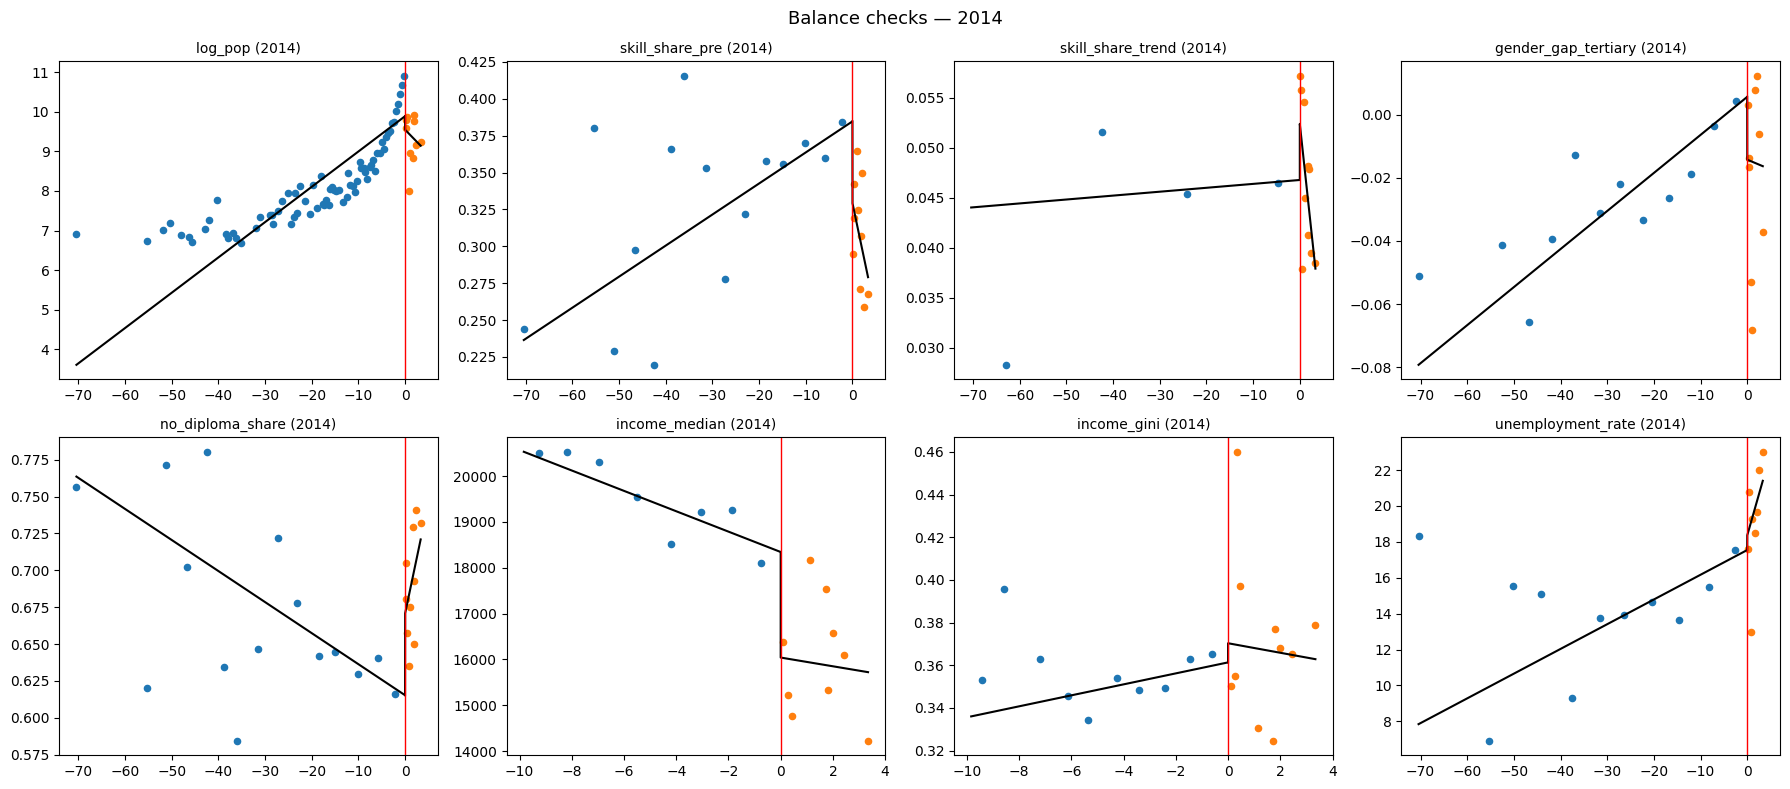

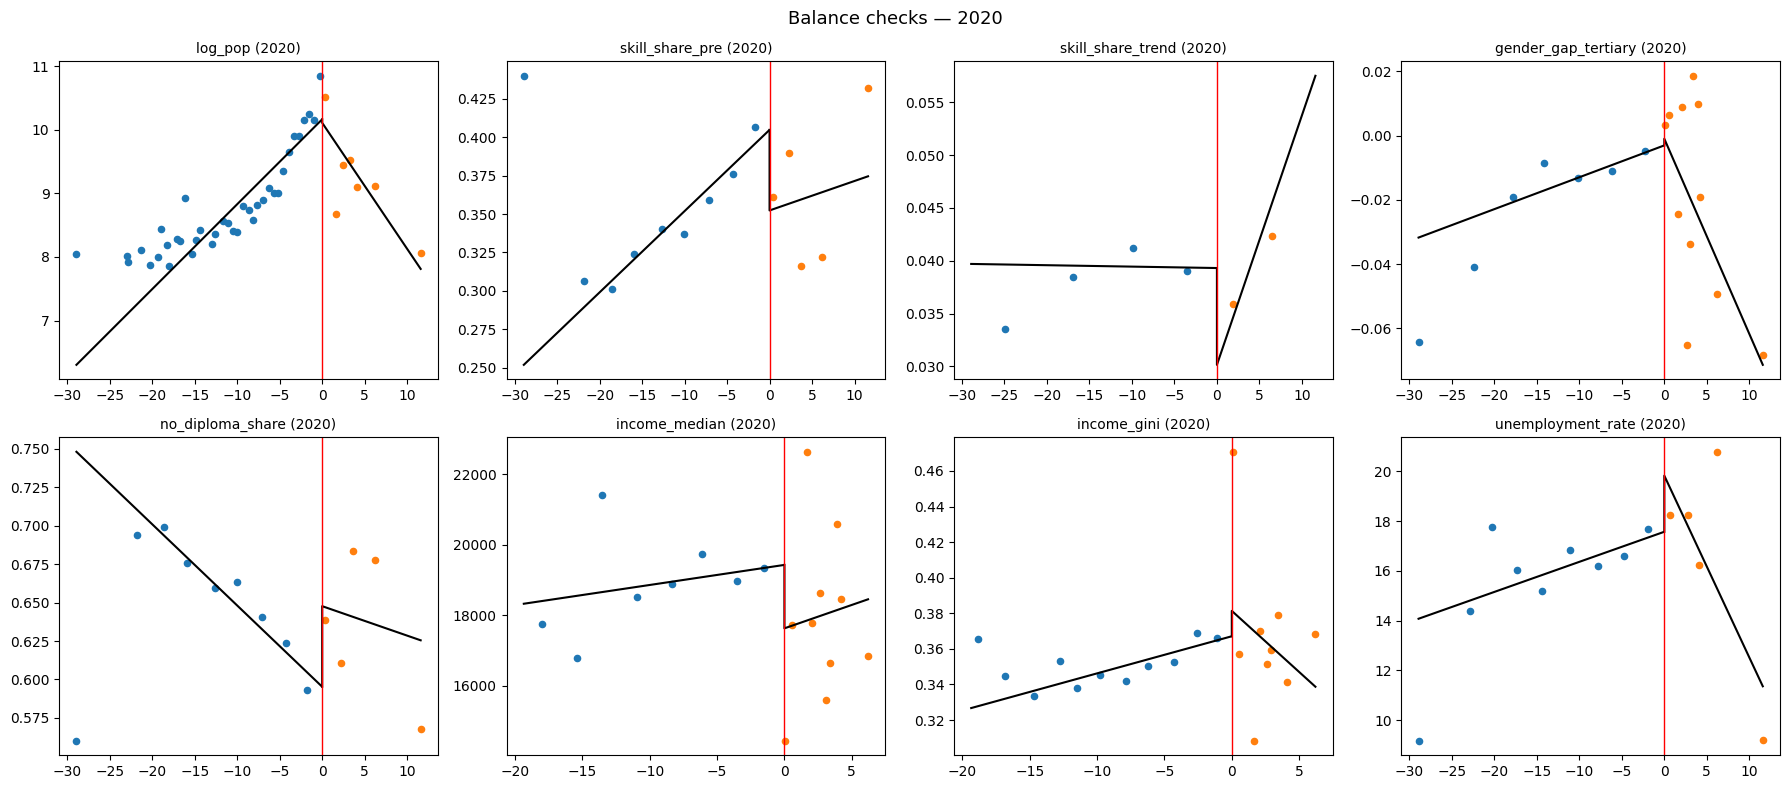

In [18]:
# ── One 8-panel figure per cycle, using rdrobust's own fit ──
for cycle in [2014, 2020]:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, cov in zip(axes.flat, covariates):
        plot_balance_rdrobust(ax, df_rdd, cov, cycle=cycle)
    fig.suptitle(f"Balance checks — {cycle}", fontsize=13)
    plt.tight_layout()
    plt.show()

## McCrary Test

In [19]:
# ── McCrary-style manipulation test on the running variable ──
# rddensity implements the Cattaneo, Jansson & Ma (2018/2020) bias-corrected
# local-polynomial density test — the modern, standard-error-robust version
# of the original McCrary (2008) test.


# Run separately by cycle (2014, 2020): manipulation incentives, list registration
# rules, and vote-counting differ by election, so pooling would obscure a
# discontinuity that's real in only one cycle. 2008 is excluded — no observations
# above the cutoff means there is nothing to test for a jump against.
for cycle in [2014, 2020]:
    sub = df_rdd.loc[df_rdd['election_year'] == cycle, 'd_50'].dropna()

    dens = rddensity(X=sub, c=0)  # c=0: cutoff of d_50, as in the main design

    # p_jk = jackknife p-value for H0: density is continuous at the cutoff.
    # p_jk > 0.10 (conventional threshold) => no evidence of manipulation/sorting.
    p_val = dens.test.loc['p_jk']
    print(f"McCrary density test ({cycle}): p = {p_val:.3f} "
          f"({'no evidence of manipulation' if p_val > 0.10 else 'possible manipulation — investigate'})")

    # Visual check: plots the estimated density on each side of the cutoff.
    # A visible jump at d_50 = 0 is the graphical analogue of a low p-value.
    rdplotdensity(dens, sub, title=f"Density of d_50 — {cycle}")

McCrary density test (2014): p = 0.079 (possible manipulation — investigate)
McCrary density test (2020): p = 0.000 (possible manipulation — investigate)


In [20]:
# ── Diagnose asymmetry driving a failed density test ──
# Rather than tweaking bandwidth/threshold to force p > 0.05 (specification
# searching), report the raw near-cutoff counts: this tells you whether the
# failure is "narrow wins are just rare" (mechanical) vs. a sharp local jump
# right at zero (more consistent with sorting).
for cycle in [2014, 2020]:
    sub = df_rdd.loc[df_rdd['election_year'] == cycle, 'd_50'].dropna()
    n_left  = ((sub > -0.5) & (sub < 0)).sum()   # narrow losses
    n_right = ((sub >= 0)   & (sub < 0.5)).sum() # narrow wins
    print(f"{cycle}: narrow losses (-0.5,0)={n_left}, narrow wins [0,0.5)={n_right}, "
          f"total treated={(sub > 0).sum()}, total control={(sub <= 0).sum()}")

# ── Placebo density test: same test, run on the running variable of the
# PRIOR election cycle for the same communes (t-1 placebo). If the
# discontinuity/asymmetry already existed before treatment could have acted,
# it's a stable structural feature of the setting -- consistent with the
# Diff-in-Disc identifying assumption (Grembi, Nannicini & Troiano 2016) --
# rather than manipulation triggered by treatment itself.
# NOTE: requires a lagged d_50 column (e.g. 'd_50_lag') merged in beforehand.
if 'd_50_lag' in df_rdd.columns:
    for cycle in [2014, 2020]:
        sub_lag = df_rdd.loc[df_rdd['election_year'] == cycle, 'd_50_lag'].dropna()
        dens_lag = rddensity(X=sub_lag, c=0)
        p_lag = dens_lag.test.loc['p_jk']
        print(f"Placebo density test, t-1 margin ({cycle}): p = {p_lag:.3f}")

2014: narrow losses (-0.5,0)=19, narrow wins [0,0.5)=6, total treated=13, total control=500
2020: narrow losses (-0.5,0)=7, narrow wins [0,0.5)=2, total treated=13, total control=272
